In [1]:
import pandas as pd

In [2]:
import numpy as np

In [5]:
df=pd.DataFrame({'Date':['2023-01-01','2023-02-01','2023-03-01'],'Value':[10,20,30]})
df

,Date,Value
0,2023-01-01,10
1,2023-02-01,20
2,2023-03-01,30


In [6]:
df['Date']=pd.to_datetime(df['Date'])   
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    3 non-null      datetime64[us]
 1   Value   3 non-null      int64         
dtypes: datetime64[us](1), int64(1)
memory usage: 180.0 bytes


In [7]:
df

,Date,Value
0,2023-01-01,10
1,2023-02-01,20
2,2023-03-01,30


In [ ]:
df['Date']=pd.to_datetime(df['Date'],dayfirst=True)   #it will come in the format yyyy-mm-dd
df

,Date,Value
0,2023-01-01,10
1,2023-02-01,20
2,2023-03-01,30


In [11]:
df=pd.DataFrame({'Date':['2023-01-01 4:5:1','2023-02-01 20:30:00','2023-03-01 19:45:30'],'Value':[10,20,30]})
df['Date']=pd.to_datetime(df['Date'],format='%Y-%d-%m %H:%M:%S')   #it will come in the format yyyy-dd-mm
df

,Date,Value
0,2023-01-01 04:05:01,10
1,2023-01-02 20:30:00,20
2,2023-01-03 19:45:30,30


Handling parsing errors

In [6]:
df=pd.DataFrame({'Date':['2023-ma-02 4:5:1','2023-02-01 20:30:00','2023-03-01 19:45:30'],'Value':[10,20,30]})
df

,Date,Value
0,2023-ma-02 4:5:1,10
1,2023-02-01 20:30:00,20
2,2023-03-01 19:45:30,30


In [19]:
df['Date'] = pd.to_datetime(df['Date'])

In [ ]:
df['Date'] = pd.to_datetime(df['Date'], errors='ignore') #this wont work because my version do not support ignore, so it will give error

In [13]:
df['Date'] = pd.to_datetime(df['Date'], errors='coerce') #it will convert the invalid date to NaT
df

,Date,Value
0,NaT,10
1,2023-02-01 20:30:00,20
2,2023-03-01 19:45:30,30


In [4]:
import pandas as pd


In [20]:
df

,Date,Value
0,NaT,10
1,2023-02-01 20:30:00,20
2,2023-03-01 19:45:30,30


In [21]:
df=pd.DataFrame({'Date':['2023-02-02 4:5:1','2023-02-01 20:30:00','2023-03-01 19:45:30'],'Value':[10,20,30]})
df

,Date,Value
0,2023-02-02 4:5:1,10
1,2023-02-01 20:30:00,20
2,2023-03-01 19:45:30,30


In [31]:
df=pd.DataFrame({'year':[2023,2023],'month':[2,2],'day':[2,1]})
df['Date'] = pd.to_datetime(df)
df

,year,month,day,Date
0,2023,2,2,2023-02-02
1,2023,2,1,2023-02-01


In [30]:
df['Date'] = pd.to_datetime(df) #why am i getting error because i am not specifying the column name, so it is trying to convert the whole dataframe to datetime, which is not possible. so we need to specify the column name.

In [35]:
df=pd.DataFrame({'name':['adithi','krithika','laary'],'dob':['08-02-2000','09-03-2001','10-04-2002']})
df

,name,dob
0,adithi,08-02-2000
1,krithika,09-03-2001
2,laary,10-04-2002


In [32]:
df.info()
df

<class 'pandas.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   year    2 non-null      int64         
 1   month   2 non-null      int64         
 2   day     2 non-null      int64         
 3   Date    2 non-null      datetime64[us]
dtypes: datetime64[us](1), int64(3)
memory usage: 196.0 bytes


,year,month,day,Date
0,2023,2,2,2023-02-02
1,2023,2,1,2023-02-01


In [38]:
# dob to datetime
df['dob'] = pd.to_datetime(df['dob'], format='%d-%m-%Y')
df

,name,dob
0,adithi,2000-02-08
1,krithika,2001-03-09
2,laary,2002-04-10


In [39]:
df['year']=df['dob'].dt.year
df['month']=df['dob'].dt.month
df['day']=df['dob'].dt.day
df


,name,dob,year,month,day
0,adithi,2000-02-08,2000,2,8
1,krithika,2001-03-09,2001,3,9
2,laary,2002-04-10,2002,4,10


get the week of year, the day of week and leap year

In [41]:
df['day_of_week']=df['dob'].dt.dayofweek
df['is_leap_year']=df['dob'].dt.is_leap_year
df

,name,dob,year,month,day,day_of_week,is_leap_year
0,adithi,2000-02-08,2000,2,8,1,True
1,krithika,2001-03-09,2001,3,9,4,False
2,laary,2002-04-10,2002,4,10,2,False


In [42]:
df['dob'].dt.weekday

0    1
1    4
2    2
Name: dob, dtype: int32

In [43]:
dw_mapping={
    0:'Monday',
    1:'Tuesday',
    2:'Wednesday',
    3:'Thursaday',
    4:'Friday',
    5:'Saturday',
    6:'Sunday'
}
df['day_of_week_name']=df['dob'].dt.weekday.map(dw_mapping)
df

,name,dob,year,month,day,day_of_week,is_leap_year,day_of_week_name
0,adithi,2000-02-08,2000,2,8,1,True,Tuesday
1,krithika,2001-03-09,2001,3,9,4,False,Friday
2,laary,2002-04-10,2002,4,10,2,False,Wednesday


Get the age from the dob

In [50]:
#get age from dob
today=pd.to_datetime('today')
df['age']=today.year-df['dob'].dt.year
df

,name,dob,year,month,day,day_of_week,is_leap_year,day_of_week_name,age
0,adithi,2000-02-08,2000,2,8,1,True,Tuesday,26
1,krithika,2001-03-09,2001,3,9,4,False,Friday,25
2,laary,2002-04-10,2002,4,10,2,False,Wednesday,24


In [52]:
#year difference
today=pd.to_datetime('today')
diff_y=today.year-df['dob'].dt.year

#havent had birthday
b_md=df['dob'].apply(lambda x:(x.month,x.day))
no_birthday=b_md>(today.month,today.day)

#no birthday
df['age']=diff_y-no_birthday
df

,name,dob,year,month,day,day_of_week,is_leap_year,day_of_week_name,age
0,adithi,2000-02-08,2000,2,8,1,True,Tuesday,26
1,krithika,2001-03-09,2001,3,9,4,False,Friday,25
2,laary,2002-04-10,2002,4,10,2,False,Wednesday,24


In [53]:
no_birthday

0    False
1    False
2    False
Name: dob, dtype: bool

In [2]:
import pandas as pd


MATPLOTLIB

In [5]:
 !pip install matplotlib

In [6]:
import matplotlib.pyplot as plt

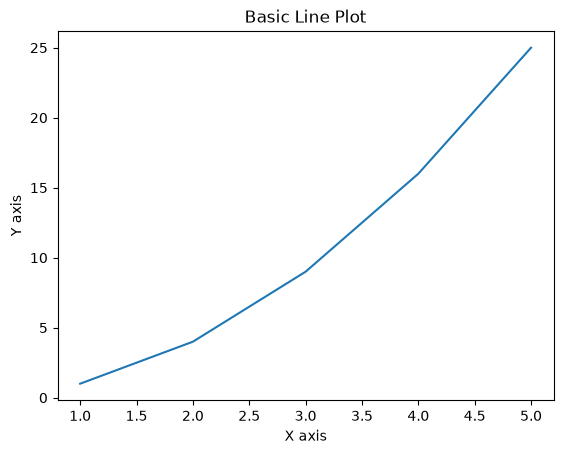

In [7]:
x=[1,2,3,4,5]
y=[1,4,9,16,25]
#create a line plot
plt.plot(x,y)
plt.xlabel('X axis')
plt.ylabel('Y axis')
plt.title("Basic Line Plot")
plt.show()

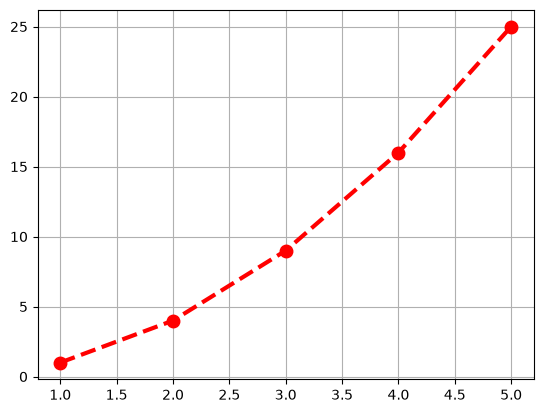

In [8]:
x=[1,2,3,4,5]
y=[1,4,9,16,25]
plt.plot(x,y,color='red',linestyle='--',marker='o',linewidth=3,markersize=9)
plt.grid(True)

Text(0.5, 1.0, 'Plot 4')

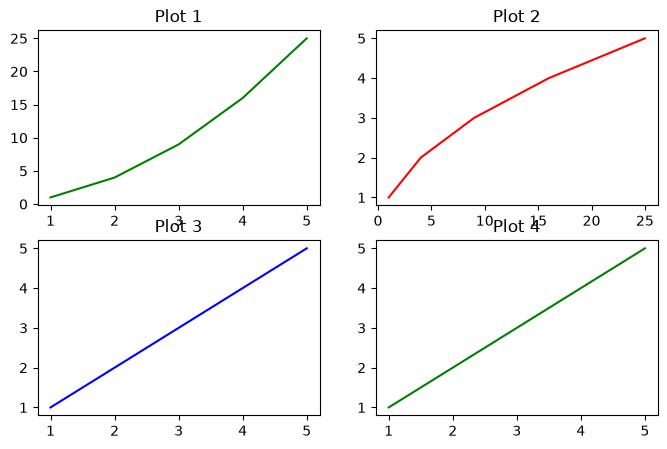

In [15]:
x=[1,2,3,4,5]
y1=[1,4,9,16,25]
y2=[1,2,3,4,5]
plt.figure(figsize=(8,5))
plt.subplot(2,2,1)
plt.plot(x,y1,color='green')
plt.title("Plot 1")

plt.subplot(2,2,2)
plt.plot(y1,x,color='red')
plt.title("Plot 2")

plt.subplot(2,2,3)
plt.plot(x,y2,color='blue')
plt.title("Plot 3")

plt.subplot(2,2,4)
plt.plot(x,y2,color='green')
plt.title("Plot 4")




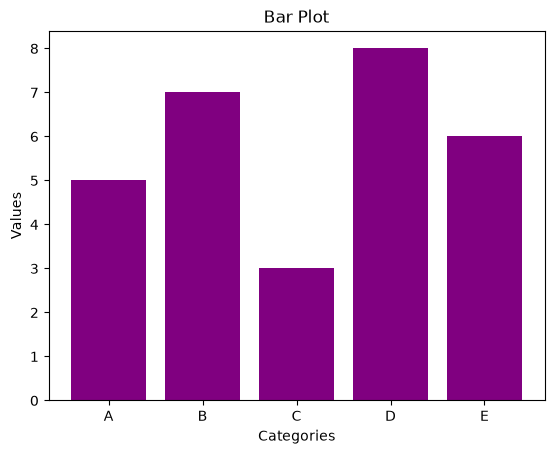

In [17]:
#bar plot
categories=['A','B','C','D','E']
values=[5,7,3,8,6]
#create a bar plot
plt.bar(categories,values,color='purple')
plt.xlabel('Categories')
plt.ylabel('Values')
plt.title('Bar Plot')
plt.show()

(array([1., 2., 3., 4., 5.]),
 array([1. , 1.8, 2.6, 3.4, 4.2, 5. ]),
 <BarContainer object of 5 artists>)

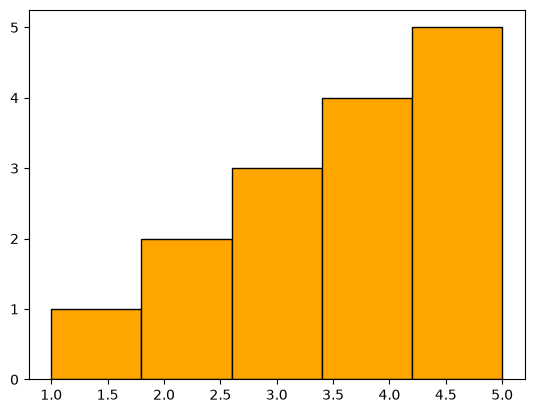

In [18]:
data=[1,2,2,3,3,3,4,4,4,4,5,5,5,5,5]
plt.hist(data,bins=5,color='orange',edgecolor='black')

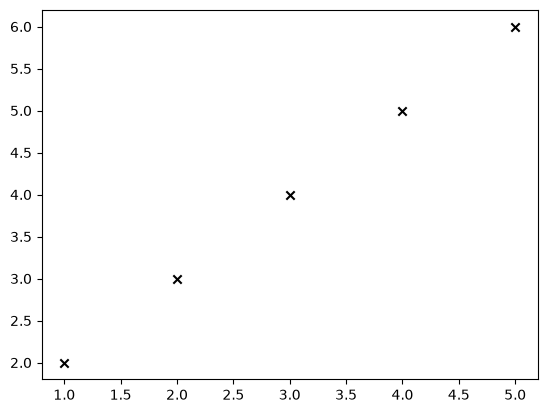

In [19]:
x=[1,2,3,4,5]
y=[2,3,4,5,6]
plt.scatter(x,y,color='black',marker='x')

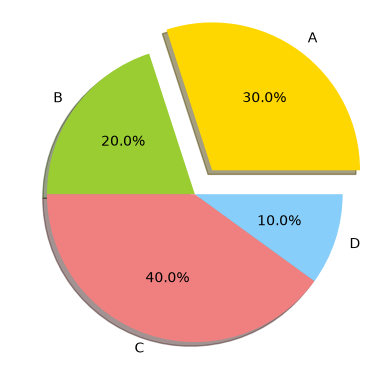

In [20]:
labels=['A','B','C','D']
sizes=[30,20,40,10]
colors=['gold','yellowgreen','lightcoral','lightskyblue']
explode=(0.2,0,0,0)     #moves out the list slice

#create a pie chart
plt.pie(sizes,explode=explode,labels=labels,colors=colors,autopct="%1.1f%%",shadow=True)

In [32]:
#sales data visualization
import pandas as pd


In [35]:
df = pd.read_csv('sales_data.csv')
df.head(5)

,Transaction ID,Date,Product Category,Product Name,Units Sold,Unit Price,Total Revenue,Region,Payment Method
0,10001,2024-01-01,Electronics,iPhone 14 Pro,2,999.99,1999.98,North America,Credit Card
1,10002,2024-01-02,Home Appliances,Dyson V11 Vacuum,1,499.99,499.99,Europe,PayPal
2,10003,2024-01-03,Clothing,Levi's 501 Jeans,3,69.99,209.97,Asia,Debit Card
3,10004,2024-01-04,Books,The Da Vinci Code,4,15.99,63.96,North America,Credit Card
4,10005,2024-01-05,Beauty Products,Neutrogena Skincare Set,1,89.99,89.99,Europe,PayPal


In [34]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    240 non-null    int64  
 1   Date              240 non-null    str    
 2   Product Category  240 non-null    str    
 3   Product Name      240 non-null    str    
 4   Units Sold        240 non-null    int64  
 5   Unit Price        240 non-null    float64
 6   Total Revenue     240 non-null    float64
 7   Region            240 non-null    str    
 8   Payment Method    240 non-null    str    
dtypes: float64(2), int64(2), str(5)
memory usage: 17.0 KB


In [25]:
!pip  install seaborn

In [1]:
import seaborn as sns

Text(0.5, 1.0, 'Plot 1')

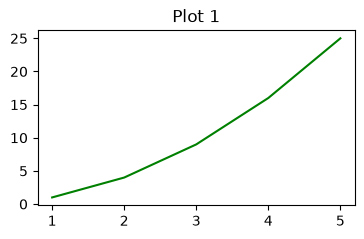

In [27]:
x=[1,2,3,4,5]
y1=[1,4,9,16,25]
y2=[1,2,3,4,5]
plt.figure(figsize=(9,5))
plt.subplot(2,2,1)
plt.plot(x,y1,color='green')
plt.title("Plot 1")

In [36]:
tips=sns.load_dataset('tips')
tips.head(4)

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2


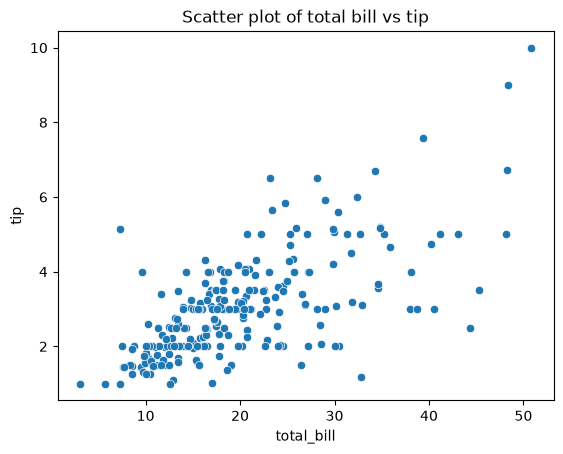

In [29]:
import matplotlib.pyplot as plt
sns.scatterplot(x='total_bill',y='tip',data=tips)
plt.title("Scatter plot of total bill vs tip")
plt.show()

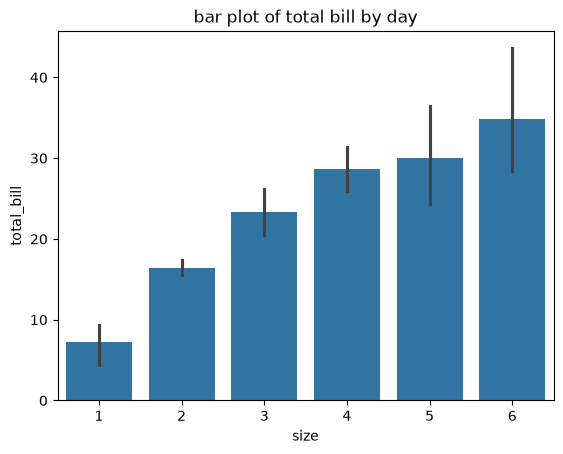

In [30]:
sns.barplot(x='size',y='total_bill',data=tips)
plt.title('bar plot of total bill by day')
plt.show()